# Skin Lesion Classification on HAM10000
**EfficientNet-B0 · class-imbalance strategies · image + metadata fusion · Grad-CAM · Gradio demo**

> **Disclaimer:** educational / coursework project. Not a medical device and not for clinical use.

## What this notebook does
1. Downloads HAM10000 (10,015 dermoscopic images, 7 diagnostic classes) and explores it.
2. Splits the data **by `lesion_id`** (stratified 70/15/15) so images of one lesion never cross splits.
3. Trains EfficientNet-B0 under several imbalance strategies:
   - **A** baseline cross-entropy
   - **B** class-weighted cross-entropy
   - **C** focal loss + balanced sampler
   - **D / E** post-hoc logit adjustment of model A (τ tuned on validation)
   - **F** multimodal fusion: image features + patient metadata (age, sex, lesion site)
4. Evaluates everything on the held-out test set, including a malignant-vs-benign screening analysis whose
   thresholds are **selected on validation data only**.
5. Explains predictions with Grad-CAM and serves the best model (F) through a Gradio demo.

## How to run
- Runtime: **Google Colab, GPU (T4)**. Total training time is roughly 10-15 minutes per model.
- You need Kaggle API credentials (the notebook asks for `kaggle.json` if the download fails). **Never commit credentials.**
- Checkpoints, split CSVs, figures and result tables are written to Google Drive (`PROJ` below).
- Seeds are fixed, but GPU kernels are not fully deterministic, so small run-to-run differences are normal.

## Contents
0. Setup · 1. Data · 2. EDA · 3. Split · 4. Preprocessing · 5. Datasets & loaders · 6. Models & training utilities ·
7. Experiments A-C · 8. Experiment F (multimodal) · 9. Training curves · 10. Test evaluation ·
11. Logit adjustment (D, E) · 12. Trade-off summary · 13. Clinical screening · 14. Grad-CAM · 15. Demo · 16. Summary

## 0. Setup

In [1]:
!nvidia-smi
!pip install -q timm grad-cam gradio scikit-learn seaborn

Tue Oct 27 07:05:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, glob, time, copy, random, subprocess, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from multiprocessing import Pool
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (f1_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve)

# The "lr_scheduler.step() before optimizer.step()" warning is harmless with AMP:
# GradScaler skips the very first optimizer step when it finds inf gradients.
warnings.filterwarnings('ignore', message='.*lr_scheduler.step.*')
sns.set_style('whitegrid')

# ---- configuration -------------------------------------------------------------------------
SEED = 42
IMG, CACHE_SIZE = 224, 256          # training crop size / size of the on-disk image cache
BS, EPOCHS, LR, NUM_WORKERS = 64, 10, 3e-4, 2
RETRAIN = True                      # False -> reuse checkpoints saved in Drive (handy after a Colab disconnect)
C_WEIGHT_IN_LOSS = False            # Experiment C: also put class weights inside the focal loss?
                                    # False (default) avoids compensating for imbalance twice (sampler + loss weights)

DATA  = '/content/ham'
CACHE = '/content/ham256'
PROJ  = '/content/drive/MyDrive/HAM10000_Project'


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


seed_everything()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', DEVICE, '| torch', torch.__version__, '| CUDA available:', torch.cuda.is_available())

device: cuda | torch 2.11.0+cu130 | CUDA available: True


Mount Google Drive so checkpoints, figures and tables survive a session reset.

In [3]:
from google.colab import drive
drive.mount('/content/drive')
for sub in ['', 'ckpt', 'figs']:
    os.makedirs(f'{PROJ}/{sub}', exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{PROJ}/figs/{name}.png', dpi=130, bbox_inches='tight')


print('project folder:', PROJ)

Mounted at /content/drive
project folder: /content/drive/MyDrive/HAM10000_Project


## 1. Data
HAM10000 ("Human Against Machine with 10000 training images"), Kaggle mirror `kmader/skin-cancer-mnist-ham10000`.
License: **CC BY-NC-SA 4.0 (non-commercial)**. Do not redistribute the images in your repository.

> Tschandl P., Rosendahl C., Kittler H. *The HAM10000 dataset, a large collection of multi-source dermatoscopic
> images of common pigmented skin lesions.* Scientific Data 5, 180161 (2018).

In [4]:
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    print((r.stdout + r.stderr)[-800:])
    return r.returncode


def kaggle_download():
    return sh(f'kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p {DATA} --unzip')


if not os.path.exists(f'{DATA}/HAM10000_metadata.csv'):
    if kaggle_download() != 0:
        from google.colab import files
        print('Kaggle download failed. Please upload your kaggle.json:')
        files.upload()
        os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
        sh('cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json')
        assert kaggle_download() == 0, 'Download failed again - check your Kaggle credentials.'
print(sorted(os.listdir(DATA)))

:29<00:01, 286MB/s]
 92%|█████████▏| 4.79G/5.20G [00:29<00:01, 287MB/s]
 93%|█████████▎| 4.83G/5.20G [00:29<00:01, 300MB/s]
 93%|█████████▎| 4.86G/5.20G [00:29<00:01, 321MB/s]
 94%|█████████▍| 4.89G/5.20G [00:30<00:01, 248MB/s]
 95%|█████████▍| 4.92G/5.20G [00:30<00:01, 266MB/s]
 95%|█████████▌| 4.95G/5.20G [00:30<00:00, 285MB/s]
 96%|█████████▌| 4.99G/5.20G [00:30<00:00, 309MB/s]
 97%|█████████▋| 5.02G/5.20G [00:30<00:00, 315MB/s]
 97%|█████████▋| 5.05G/5.20G [00:30<00:00, 308MB/s]
 98%|█████████▊| 5.08G/5.20G [00:30<00:00, 290MB/s]
 98%|█████████▊| 5.11G/5.20G [00:30<00:00, 253MB/s]
 99%|█████████▉| 5.14G/5.20G [00:31<00:00, 264MB/s]
 99%|█████████▉| 5.17G/5.20G [00:31<00:00, 140MB/s]
100%|█████████▉| 5.19G/5.20G [00:31<00:00, 115MB/s]
100%|██████████| 5.20G/5.20G [00:31<00:00, 175MB/s]

['HAM10000_images_part_1', 'HAM10000_images_part_2', 'HAM10000_metadata.csv', 'ham10000_images_part_1', 'ham10000_images_part_2', 'hmnist_28_28_L.csv', 'hmnist_28_28_RGB.csv', 'hmnist_8_8_L.csv', 'hm

Build one metadata table with the image path of every sample.
The Kaggle archive contains the image folders twice (lower- and upper-case names), so we index by `image_id`
which de-duplicates them.

In [5]:
img_paths = {os.path.splitext(os.path.basename(p))[0]: p
             for p in glob.glob(f'{DATA}/**/*.jpg', recursive=True)}

df = pd.read_csv(f'{DATA}/HAM10000_metadata.csv')
df['path'] = df['image_id'].map(img_paths)
assert df['path'].notna().all(), 'some images were not found on disk'

LESION = {
    'akiec': 'Actinic keratoses (pre-malignant)',
    'bcc':   'Basal cell carcinoma (MALIGNANT)',
    'bkl':   'Benign keratosis',
    'df':    'Dermatofibroma (benign)',
    'mel':   'Melanoma (MALIGNANT)',
    'nv':    'Melanocytic nevi (benign)',
    'vasc':  'Vascular lesion (benign)',
}
df['dx_full'] = df['dx'].map(LESION)

CLASSES = sorted(df['dx'].unique())
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df['label'] = df['dx'].map(CLASS_TO_IDX)

MEL = CLASS_TO_IDX['mel']
MAL_IDX = [CLASS_TO_IDX[c] for c in ['mel', 'bcc', 'akiec']]    # malignant / pre-malignant group for screening

print(f'images: {len(df)} | unique lesions: {df.lesion_id.nunique()} | classes: {CLASSES}')
df.head()

images: 10015 | unique lesions: 7470 | classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


,lesion_id,image_id,dx,dx_type,age,sex,localization,path,dx_full,label
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00274...,Benign keratosis,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00250...,Benign keratosis,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00267...,Benign keratosis,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham/HAM10000_images_part_1/ISIC_00256...,Benign keratosis,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham/ham10000_images_part_2/ISIC_00316...,Benign keratosis,2


## 2. Exploratory data analysis
Key points to look for: strong class imbalance (melanocytic nevi dominate), missing ages, and the fact that one
lesion can appear in several images (so images are **not** independent samples).

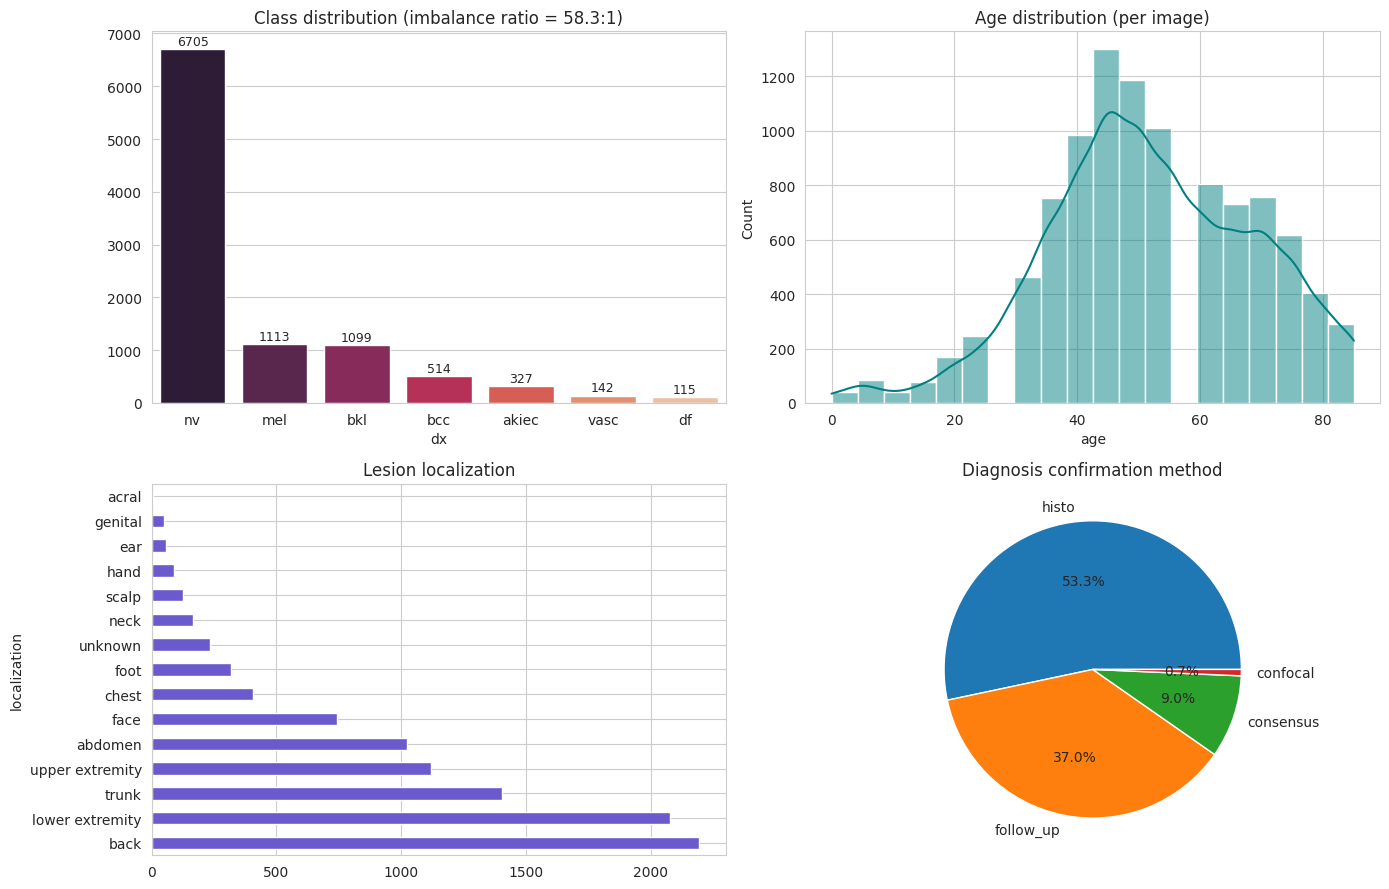

Missing age: 57 | unique lesions: 7470 | images: 10015


In [6]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

vc = df['dx'].value_counts()
sns.barplot(x=vc.index, y=vc.values, hue=vc.index, palette='rocket', legend=False, ax=ax[0, 0])
ax[0, 0].set_title(f'Class distribution (imbalance ratio = {vc.max() / vc.min():.1f}:1)')
for i, v in enumerate(vc.values):
    ax[0, 0].text(i, v + 80, str(v), ha='center', fontsize=9)

sns.histplot(df['age'].dropna(), bins=20, kde=True, ax=ax[0, 1], color='teal')
ax[0, 1].set_title('Age distribution (per image)')

df['localization'].value_counts().plot(kind='barh', ax=ax[1, 0], color='slateblue')
ax[1, 0].set_title('Lesion localization')

df['dx_type'].value_counts().plot(kind='pie', autopct='%1.1f%%', ax=ax[1, 1])
ax[1, 1].set_ylabel('')
ax[1, 1].set_title('Diagnosis confirmation method')

save_fig('eda')
plt.show()
print('Missing age:', df['age'].isna().sum(), '| unique lesions:', df['lesion_id'].nunique(), '| images:', len(df))

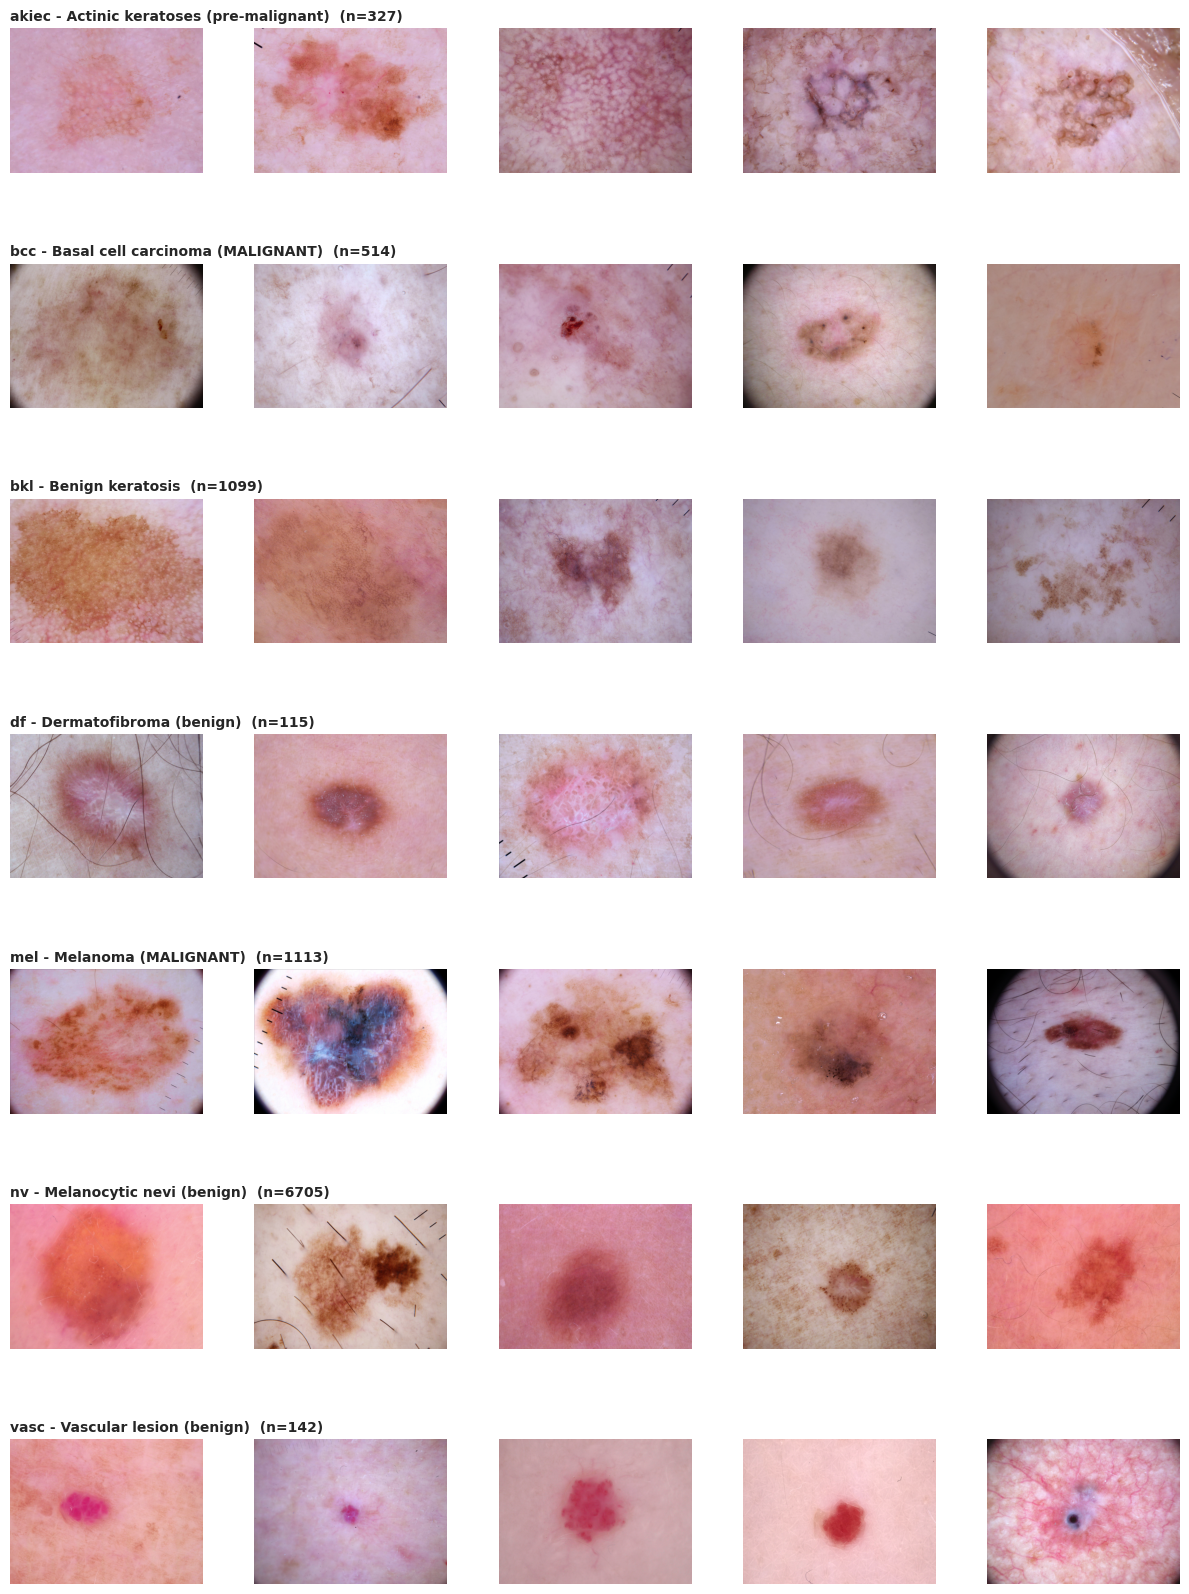

In [7]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(12, 2.4 * NUM_CLASSES))
for r, c in enumerate(CLASSES):
    sub = df[df['dx'] == c].sample(5, random_state=SEED)
    for k, (_, row) in enumerate(sub.iterrows()):
        axes[r, k].imshow(Image.open(row['path']))
        axes[r, k].axis('off')
    axes[r, 0].set_title(f"{c} - {LESION[c]}  (n={(df['dx'] == c).sum()})", loc='left', fontsize=10, fontweight='bold')
save_fig('samples')
plt.show()

## 3. Train / validation / test split
HAM10000 has no patient ID, but it has `lesion_id`. Several images can show the same lesion, so splitting by image
would leak near-duplicates into the test set. We therefore split **by lesion**, stratified on the diagnosis.

Limitation: the same *patient* may still own different lesions in different splits (patient IDs are not available).

In [8]:
lesions = df.groupby('lesion_id')['label'].first().reset_index()
tr_ids, tmp_ids = train_test_split(lesions, test_size=0.30, stratify=lesions['label'], random_state=SEED)
va_ids, te_ids = train_test_split(tmp_ids, test_size=0.50, stratify=tmp_ids['label'], random_state=SEED)

train_df = df[df.lesion_id.isin(tr_ids.lesion_id)].reset_index(drop=True)
val_df = df[df.lesion_id.isin(va_ids.lesion_id)].reset_index(drop=True)
test_df = df[df.lesion_id.isin(te_ids.lesion_id)].reset_index(drop=True)

print(f'Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}')
assert not set(train_df.lesion_id) & set(val_df.lesion_id)
assert not set(train_df.lesion_id) & set(test_df.lesion_id)
assert not set(val_df.lesion_id) & set(test_df.lesion_id)
print('OK: no lesion appears in more than one split')

counts = pd.DataFrame({n: d['dx'].value_counts() for n, d in
                       [('train', train_df), ('val', val_df), ('test', test_df)]}).loc[CLASSES]
print(counts)

Train 6981 | Val 1532 | Test 1502
OK: no lesion appears in more than one split
       train   val  test
dx                      
akiec    222    53    52
bcc      361    82    71
bkl      772   160   167
df        71    24    20
mel      773   173   167
nv      4683  1018  1004
vasc      99    22    21


## 4. Preprocessing
- **Image cache:** every image is resized once to 256x256 and stored on local disk, which removes JPEG decoding of
  600x450 originals from the training loop (I/O speed-up). The resize does not preserve the aspect ratio;
  the demo applies exactly the same resize so inference matches training.
- **Missing age:** filled with the **training-set** median (no leakage from val/test).

In [9]:
os.makedirs(CACHE, exist_ok=True)


def resize_one(p):
    out = f'{CACHE}/{os.path.basename(p)}'
    if not os.path.exists(out):
        Image.open(p).convert('RGB').resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR).save(out, quality=95)
    return out


unique_paths = list(img_paths.values())
with Pool(os.cpu_count()) as pool:
    list(tqdm(pool.imap_unordered(resize_one, unique_paths, chunksize=64), total=len(unique_paths)))
print('cached images:', len(os.listdir(CACHE)))

AGE_MED = train_df['age'].median()
for d in (train_df, val_df, test_df):
    d['path'] = CACHE + '/' + d['image_id'] + '.jpg'
    d['age'] = d['age'].fillna(AGE_MED)

train_df.to_csv(f'{PROJ}/train.csv', index=False)
val_df.to_csv(f'{PROJ}/val.csv', index=False)
test_df.to_csv(f'{PROJ}/test.csv', index=False)
print('median age (train) =', AGE_MED)

  0%|          | 0/10015 [00:00<?, ?it/s]

cached images: 10015
median age (train) = 50.0


## 5. Datasets, augmentation and loaders
- **Train augmentation:** random resized crop, horizontal/vertical flips, rotation (30°), colour jitter
  (camera/lighting variation) and random erasing.
- **Eval transform:** resize + centre crop only.
- **Metadata features** (used by experiment F): standardized age + one-hot sex + one-hot lesion localization.
  Scalers/encoders are fitted on the training set only.
- **Class weights:** inverse frequency, `N / (K * n_c)`.

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(IMG, scale=(0.7, 1.0)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
    T.RandomRotation(30),
    T.ColorJitter(0.2, 0.2, 0.2, 0.05),
    T.ToTensor(), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25),
])
eval_tf = T.Compose([T.Resize(IMG), T.CenterCrop(IMG), T.ToTensor(), T.Normalize(MEAN, STD)])


def inv(t):
    # undo normalization: CHW tensor -> HWC float array in [0, 1] (for plotting)
    return (t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)


# ---- metadata features ---------------------------------------------------------------------
CAT = ['sex', 'localization']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(train_df[CAT])
age_sc = StandardScaler().fit(train_df[['age']])


def make_meta(d):
    return np.hstack([age_sc.transform(d[['age']]), ohe.transform(d[CAT])]).astype('float32')


META = {'train': make_meta(train_df), 'val': make_meta(val_df), 'test': make_meta(test_df)}
META_DIM = META['train'].shape[1]
print('META_DIM =', META_DIM)


# ---- dataset / loaders ---------------------------------------------------------------------
class SkinDS(Dataset):
    # returns (image, label) or, when `meta` is given, (image, metadata, label)
    def __init__(self, df, tf, meta=None):
        self.df = df.reset_index(drop=True)
        self.tf, self.meta = tf, meta
        self.paths = self.df['path'].tolist()
        self.labels = self.df['label'].astype(int).tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        x = self.tf(Image.open(self.paths[i]).convert('RGB'))
        if self.meta is None:
            return x, self.labels[i]
        return x, torch.from_numpy(self.meta[i]), self.labels[i]


def make_loader(df, tf, shuffle=False, sampler=None, meta=None):
    return DataLoader(SkinDS(df, tf, meta), batch_size=BS,
                      shuffle=(shuffle and sampler is None), sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      drop_last=(shuffle or sampler is not None))


# class weights and prior (training distribution)
cnt = train_df['label'].value_counts().sort_index().values
cls_w = torch.tensor(cnt.sum() / (NUM_CLASSES * cnt), dtype=torch.float32, device=DEVICE)
PRIOR = cnt / cnt.sum()
print('class weights:', dict(zip(CLASSES, cls_w.cpu().numpy().round(2))))

# image-only loaders
train_dl = make_loader(train_df, train_tf, shuffle=True)
val_dl = make_loader(val_df, eval_tf)
test_dl = make_loader(test_df, eval_tf)

# balanced sampler (experiment C): sample each training image with probability proportional to its class weight
sample_w = cls_w.cpu().numpy()[train_df['label'].values]
sampler = WeightedRandomSampler(torch.as_tensor(sample_w, dtype=torch.double),
                                num_samples=len(sample_w), replacement=True)
train_dl_bal = make_loader(train_df, train_tf, sampler=sampler)

# image + metadata loaders (experiment F)
train_mm = make_loader(train_df, train_tf, shuffle=True, meta=META['train'])
val_mm = make_loader(val_df, eval_tf, meta=META['val'])
test_mm = make_loader(test_df, eval_tf, meta=META['test'])
print('batches  train/val/test:', len(train_dl), len(val_dl), len(test_dl))

META_DIM = 19
class weights: {'akiec': np.float32(4.49), 'bcc': np.float32(2.76), 'bkl': np.float32(1.29), 'df': np.float32(14.05), 'mel': np.float32(1.29), 'nv': np.float32(0.21), 'vasc': np.float32(10.07)}
batches  train/val/test: 109 24 24


## 6. Models, losses and training utilities
- **Image model:** EfficientNet-B0 (timm, ImageNet-pretrained), 7-way head.
- **Multimodal model:** EfficientNet-B0 feature extractor (1,280-d) concatenated with a small MLP over the 19
  metadata features, followed by a linear classifier.
- **Training:** AdamW, OneCycleLR, mixed precision, 10 epochs. The checkpoint with the best **validation macro-F1**
  is kept (the test set is never used for model selection).
- **Metrics:** accuracy, macro-F1, balanced accuracy and melanoma recall.

In [11]:
def build_image_model():
    return timm.create_model('efficientnet_b0', pretrained=True, num_classes=NUM_CLASSES).to(DEVICE)


class MultimodalNet(nn.Module):
    def __init__(self, meta_dim, n_cls):
        super().__init__()
        self.cnn = timm.create_model('efficientnet_b0', pretrained=True, num_classes=0)
        d = self.cnn.num_features                      # 1280
        self.mlp = nn.Sequential(nn.Linear(meta_dim, 64), nn.BatchNorm1d(64), nn.ReLU(),
                                 nn.Dropout(0.3), nn.Linear(64, 64), nn.ReLU())
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(d + 64, n_cls))

    def forward(self, x, m):
        return self.head(torch.cat([self.cnn(x), self.mlp(m)], dim=1))


class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weight=None):
        super().__init__()
        self.g, self.w = gamma, weight

    def forward(self, logits, y):
        ce = F.cross_entropy(logits, y, weight=self.w, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.g * ce).mean()

In [12]:
RENAME = {'acc': 'Accuracy', 'f1': 'Macro-F1', 'bacc': 'Balanced-Acc', 'mel_rec': 'Melanoma-Recall'}


def metrics_from_pred(pred, Y):
    n_mel = max(int((Y == MEL).sum()), 1)
    return dict(acc=float((pred == Y).mean()),
                f1=float(f1_score(Y, pred, average='macro')),
                bacc=float(balanced_accuracy_score(Y, pred)),
                mel_rec=float(((pred == MEL) & (Y == MEL)).sum() / n_mel))


def unpack(batch, multimodal):
    if multimodal:
        x, m, y = batch
        return (x.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True)), y
    x, y = batch
    return (x.to(DEVICE, non_blocking=True),), y


@torch.no_grad()
def predict_probs(model, dl, multimodal=False):
    model.eval()
    P, Y = [], []
    for batch in dl:
        inputs, y = unpack(batch, multimodal)
        with torch.autocast('cuda', torch.float16, enabled=(DEVICE.type == 'cuda')):
            out = model(*inputs)
        P.append(out.float().softmax(1).cpu())
        Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()


def train_model(tag, model, criterion, train_loader, val_loader, multimodal=False, epochs=EPOCHS, lr=LR):
    ckpt, hist_path = f'{PROJ}/ckpt/{tag}.pt', f'{PROJ}/ckpt/{tag}_hist.csv'
    if not RETRAIN and os.path.exists(ckpt) and os.path.exists(hist_path):
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        print(f'[{tag}] loaded existing checkpoint (set RETRAIN = True to retrain)')
        return model, pd.read_csv(hist_path)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))
    best, best_state, hist = -1.0, None, []

    for ep in range(epochs):
        model.train()
        running, t0 = 0.0, time.time()
        for batch in train_loader:
            inputs, y = unpack(batch, multimodal)
            y = y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', torch.float16, enabled=(DEVICE.type == 'cuda')):
                loss = criterion(model(*inputs), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sch.step()
            running += loss.item()

        P, Y = predict_probs(model, val_loader, multimodal)
        m = metrics_from_pred(P.argmax(1), Y)
        hist.append(dict(ep=ep + 1, loss=running / len(train_loader), **m))
        print(f"[{tag}] ep{ep + 1:02d} loss {running / len(train_loader):.3f} | acc {m['acc']:.4f} "
              f"F1 {m['f1']:.4f} bAcc {m['bacc']:.4f} melR {m['mel_rec']:.3f} | {time.time() - t0:.0f}s")
        if m['f1'] > best:
            best, best_state = m['f1'], copy.deepcopy(model.state_dict())
            torch.save(best_state, ckpt)

    model.load_state_dict(best_state)          # return the best epoch, not the last one
    hist = pd.DataFrame(hist)
    hist.to_csv(hist_path, index=False)
    print(f'DONE {tag}: best val macro-F1 = {best:.4f}')
    return model, hist

## 7. Experiments A-C (image-only)
| Run | Loss | Sampling |
|---|---|---|
| **A** | cross-entropy (label smoothing 0.05) | uniform |
| **B** | class-weighted cross-entropy (label smoothing 0.05) | uniform |
| **C** | focal loss (γ = 2) | class-balanced `WeightedRandomSampler` |

In C the sampler already re-balances the classes, so by default the class weights are **not** repeated inside the
loss (`C_WEIGHT_IN_LOSS = False`). Applying both over-corrects and collapses accuracy.

In [13]:
model_A, hist_A = train_model('A_baseline', build_image_model(),
                              nn.CrossEntropyLoss(label_smoothing=0.05), train_dl, val_dl)

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[A_baseline] ep01 loss 2.417 | acc 0.5516 F1 0.2237 bAcc 0.2413 melR 0.202 | 77s
[A_baseline] ep02 loss 1.166 | acc 0.6873 F1 0.3901 bAcc 0.4169 melR 0.254 | 60s
[A_baseline] ep03 loss 0.895 | acc 0.7650 F1 0.4927 bAcc 0.4937 melR 0.324 | 59s
[A_baseline] ep04 loss 0.758 | acc 0.7826 F1 0.5173 bAcc 0.4862 melR 0.451 | 59s
[A_baseline] ep05 loss 0.669 | acc 0.7852 F1 0.5236 bAcc 0.5243 melR 0.445 | 60s
[A_baseline] ep06 loss 0.619 | acc 0.7885 F1 0.5478 bAcc 0.5324 melR 0.514 | 60s
[A_baseline] ep07 loss 0.576 | acc 0.7787 F1 0.5550 bAcc 0.5400 melR 0.584 | 60s
[A_baseline] ep08 loss 0.544 | acc 0.7872 F1 0.5784 bAcc 0.5577 melR 0.543 | 59s
[A_baseline] ep09 loss 0.517 | acc 0.7918 F1 0.5713 bAcc 0.5468 melR 0.532 | 63s
[A_baseline] ep10 loss 0.516 | acc 0.7918 F1 0.5807 bAcc 0.5476 melR 0.509 | 59s
DONE A_baseline: best val macro-F1 = 0.5807


In [14]:
model_B, hist_B = train_model('B_weighted', build_image_model(),
                              nn.CrossEntropyLoss(weight=cls_w, label_smoothing=0.05), train_dl, val_dl)

[B_weighted] ep01 loss 3.991 | acc 0.2409 F1 0.1786 bAcc 0.3249 melR 0.231 | 60s
[B_weighted] ep02 loss 2.610 | acc 0.3061 F1 0.2541 bAcc 0.4241 melR 0.376 | 59s
[B_weighted] ep03 loss 1.964 | acc 0.3185 F1 0.3044 bAcc 0.4567 melR 0.295 | 59s
[B_weighted] ep04 loss 1.687 | acc 0.3740 F1 0.3317 bAcc 0.5650 melR 0.694 | 60s
[B_weighted] ep05 loss 1.522 | acc 0.4471 F1 0.3809 bAcc 0.5742 melR 0.740 | 60s
[B_weighted] ep06 loss 1.432 | acc 0.4967 F1 0.4025 bAcc 0.5945 melR 0.665 | 59s
[B_weighted] ep07 loss 1.348 | acc 0.5255 F1 0.4224 bAcc 0.5958 melR 0.676 | 60s
[B_weighted] ep08 loss 1.308 | acc 0.5287 F1 0.4266 bAcc 0.6126 melR 0.671 | 61s
[B_weighted] ep09 loss 1.290 | acc 0.5300 F1 0.4344 bAcc 0.6268 melR 0.665 | 62s
[B_weighted] ep10 loss 1.245 | acc 0.5444 F1 0.4329 bAcc 0.6169 melR 0.607 | 60s
DONE B_weighted: best val macro-F1 = 0.4344


In [15]:
focal = FocalLoss(gamma=2.0, weight=cls_w if C_WEIGHT_IN_LOSS else None)
model_C, hist_C = train_model('C_focal_sampler', build_image_model(), focal, train_dl_bal, val_dl)

[C_focal_sampler] ep01 loss 2.727 | acc 0.4608 F1 0.2921 bAcc 0.3934 melR 0.364 | 59s
[C_focal_sampler] ep02 loss 0.949 | acc 0.6266 F1 0.4239 bAcc 0.5105 melR 0.532 | 59s
[C_focal_sampler] ep03 loss 0.530 | acc 0.7056 F1 0.5132 bAcc 0.5421 melR 0.335 | 60s
[C_focal_sampler] ep04 loss 0.342 | acc 0.6495 F1 0.5092 bAcc 0.5754 melR 0.578 | 61s
[C_focal_sampler] ep05 loss 0.250 | acc 0.7076 F1 0.5457 bAcc 0.5641 melR 0.734 | 60s
[C_focal_sampler] ep06 loss 0.210 | acc 0.7461 F1 0.5793 bAcc 0.5919 melR 0.462 | 59s
[C_focal_sampler] ep07 loss 0.173 | acc 0.7232 F1 0.5634 bAcc 0.6020 melR 0.584 | 59s
[C_focal_sampler] ep08 loss 0.154 | acc 0.7448 F1 0.5985 bAcc 0.6156 melR 0.676 | 59s
[C_focal_sampler] ep09 loss 0.138 | acc 0.7298 F1 0.5928 bAcc 0.6155 melR 0.694 | 59s
[C_focal_sampler] ep10 loss 0.140 | acc 0.7448 F1 0.5881 bAcc 0.6050 melR 0.682 | 59s
DONE C_focal_sampler: best val macro-F1 = 0.5985


## 8. Experiment F: image + metadata fusion
Same backbone, optimizer, schedule, loss and epochs as the baseline (A); the only change is the extra metadata
branch, so the comparison A vs F isolates the effect of the metadata.

In [16]:
model_F, hist_F = train_model('F_multimodal', MultimodalNet(META_DIM, NUM_CLASSES).to(DEVICE),
                              nn.CrossEntropyLoss(label_smoothing=0.05), train_mm, val_mm, multimodal=True)

[F_multimodal] ep01 loss 1.638 | acc 0.7121 F1 0.2596 bAcc 0.2594 melR 0.220 | 60s
[F_multimodal] ep02 loss 0.869 | acc 0.7781 F1 0.4513 bAcc 0.4533 melR 0.347 | 60s
[F_multimodal] ep03 loss 0.720 | acc 0.8029 F1 0.5779 bAcc 0.5700 melR 0.457 | 61s
[F_multimodal] ep04 loss 0.644 | acc 0.8081 F1 0.5784 bAcc 0.5423 melR 0.422 | 62s
[F_multimodal] ep05 loss 0.587 | acc 0.8081 F1 0.6311 bAcc 0.5928 melR 0.549 | 60s
[F_multimodal] ep06 loss 0.527 | acc 0.8120 F1 0.6402 bAcc 0.6154 melR 0.734 | 62s
[F_multimodal] ep07 loss 0.488 | acc 0.8101 F1 0.6199 bAcc 0.5868 melR 0.630 | 59s
[F_multimodal] ep08 loss 0.452 | acc 0.8244 F1 0.6287 bAcc 0.5875 melR 0.642 | 59s
[F_multimodal] ep09 loss 0.427 | acc 0.8205 F1 0.6422 bAcc 0.5983 melR 0.607 | 59s
[F_multimodal] ep10 loss 0.414 | acc 0.8211 F1 0.6294 bAcc 0.5877 melR 0.590 | 59s
DONE F_multimodal: best val macro-F1 = 0.6422


## 9. Training curves (validation)

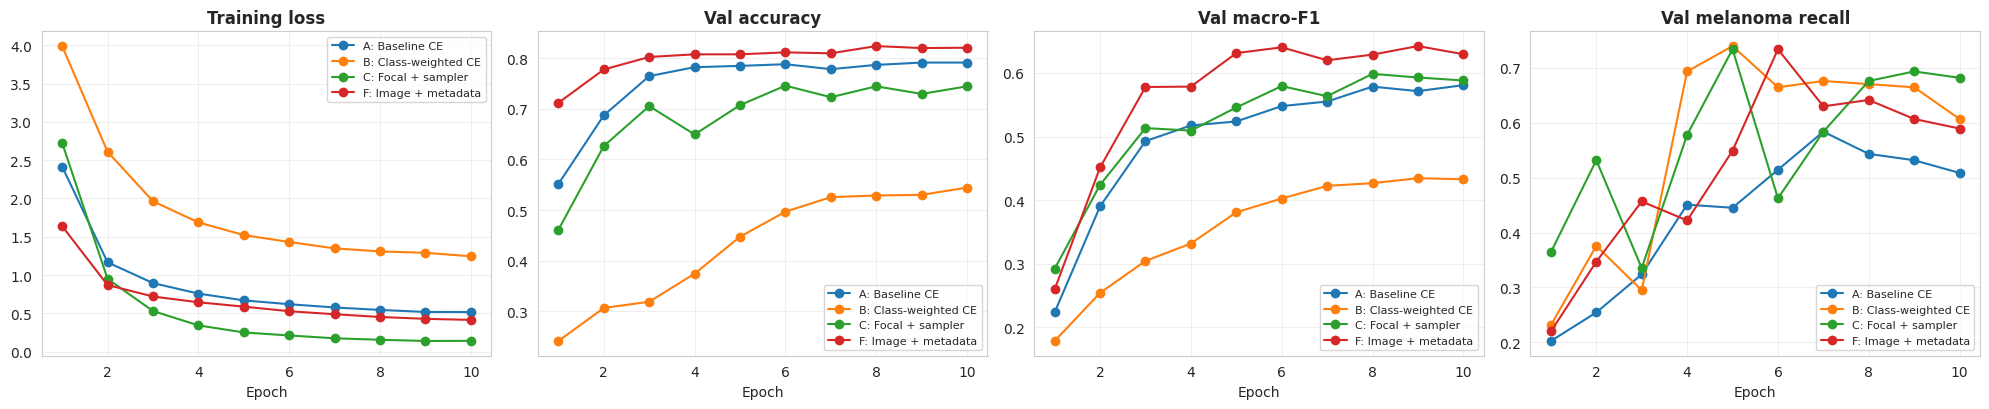

In [17]:
runs = {'A: Baseline CE': hist_A, 'B: Class-weighted CE': hist_B,
        'C: Focal + sampler': hist_C, 'F: Image + metadata': hist_F}
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
for name, h in runs.items():
    for a, col in zip(ax, ['loss', 'acc', 'f1', 'mel_rec']):
        a.plot(h['ep'], h[col], marker='o', label=name)
for a, t in zip(ax, ['Training loss', 'Val accuracy', 'Val macro-F1', 'Val melanoma recall']):
    a.set_title(t, fontweight='bold')
    a.set_xlabel('Epoch')
    a.grid(alpha=.3)
    a.legend(fontsize=8)
save_fig('curves')
plt.show()

## 10. Test-set evaluation
Each model is evaluated once on the test set using its best-validation checkpoint.
Validation probabilities are stored too, because later steps (logit adjustment, screening thresholds)
must be tuned on validation data only.

In [18]:
MODELS = {'A_baseline': (model_A, False), 'B_weighted': (model_B, False),
          'C_focal_sampler': (model_C, False), 'F_multimodal': (model_F, True)}

PROBS = {}
for tag, (mdl, mm) in MODELS.items():
    Pv, Yv_ = predict_probs(mdl, val_mm if mm else val_dl, mm)
    Pt, Yt_ = predict_probs(mdl, test_mm if mm else test_dl, mm)
    PROBS[tag] = dict(Pv=Pv, Yv=Yv_, Pt=Pt, Yt=Yt_)

Yv, Yt = PROBS['A_baseline']['Yv'], PROBS['A_baseline']['Yt']
assert all((d['Yv'] == Yv).all() and (d['Yt'] == Yt).all() for d in PROBS.values())


def result_row(name, pred, Y):
    m = metrics_from_pred(pred, Y)
    return {'Model': name, **{RENAME[k]: round(v, 4) for k, v in m.items()}}


res_df = pd.DataFrame([result_row(tag, d['Pt'].argmax(1), Yt) for tag, d in PROBS.items()])
print(res_df.to_string(index=False))

          Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
     A_baseline    0.7983    0.6449        0.6130           0.4731
     B_weighted    0.5233    0.4407        0.6854           0.5988
C_focal_sampler    0.7324    0.6383        0.6647           0.6347
   F_multimodal    0.8329    0.6861        0.6469           0.6108


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (tag, d) in zip(axes.ravel(), PROBS.items()):
    pred = d['Pt'].argmax(1)
    cm = confusion_matrix(Yt, pred, normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False, vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_title(f"{tag}\nmacro-F1 = {f1_score(Yt, pred, average='macro'):.3f}", fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
save_fig('confusion')
plt.show()

In [ ]:
best_tag = res_df.sort_values('Macro-F1', ascending=False).iloc[0]['Model']
pred_best = PROBS[best_tag]['Pt'].argmax(1)
print(f'===== best model by test macro-F1: {best_tag} =====\n')
print(classification_report(Yt, pred_best, target_names=CLASSES, digits=4))
rep = pd.DataFrame(classification_report(Yt, pred_best, target_names=CLASSES, digits=4, output_dict=True)).T
rep.to_csv(f'{PROJ}/classification_report.csv')

## 11. Post-hoc logit adjustment (D and E)
Instead of retraining, shift the baseline's decisions toward rare classes:

`prediction = argmax( log p(y|x) - τ · log π(y) )`, where π is the training class prior.

τ is tuned **on the validation set** (grid 0 ... 1.5), once for macro-F1 (**D**) and once for balanced accuracy (**E**).
τ = 0 is the unmodified baseline; larger τ trades overall accuracy for minority-class recall.

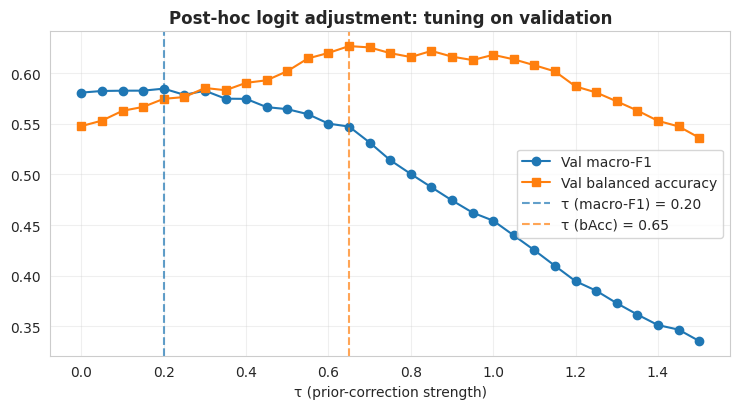

tau (macro-F1) = 0.20 | tau (bAcc) = 0.65


In [21]:
Pv_A, Pt_A = PROBS['A_baseline']['Pv'], PROBS['A_baseline']['Pt']


def logit_adjust(P, tau):
    return (np.log(P + 1e-12) - tau * np.log(PRIOR)).argmax(1)


rows = []
for tau in np.arange(0, 1.55, 0.05):
    pv = logit_adjust(Pv_A, tau)
    rows.append(dict(tau=round(float(tau), 2),
                     val_f1=f1_score(Yv, pv, average='macro'),
                     val_bacc=balanced_accuracy_score(Yv, pv)))
tdf = pd.DataFrame(rows)
tau_f1 = float(tdf.loc[tdf['val_f1'].idxmax(), 'tau'])
tau_b = float(tdf.loc[tdf['val_bacc'].idxmax(), 'tau'])

plt.figure(figsize=(7.5, 4.2))
plt.plot(tdf.tau, tdf.val_f1, marker='o', label='Val macro-F1')
plt.plot(tdf.tau, tdf.val_bacc, marker='s', label='Val balanced accuracy')
plt.axvline(tau_f1, ls='--', c='tab:blue', alpha=.7, label=f'τ (macro-F1) = {tau_f1:.2f}')
plt.axvline(tau_b, ls='--', c='tab:orange', alpha=.7, label=f'τ (bAcc) = {tau_b:.2f}')
plt.xlabel('τ (prior-correction strength)')
plt.legend()
plt.grid(alpha=.3)
plt.title('Post-hoc logit adjustment: tuning on validation', fontweight='bold')
save_fig('tau_tuning')
plt.show()
print(f'tau (macro-F1) = {tau_f1:.2f} | tau (bAcc) = {tau_b:.2f}')

In [22]:
row_D = result_row(f'D_A+LogitAdj(tau={tau_f1:.2f})', logit_adjust(Pt_A, tau_f1), Yt)
row_E = result_row(f'E_A+LogitAdj(tau={tau_b:.2f}, bAcc-opt)', logit_adjust(Pt_A, tau_b), Yt)

# table order: A, B, C, D, E, F
final_df = pd.concat([res_df.iloc[:3], pd.DataFrame([row_D, row_E]), res_df.iloc[[3]]], ignore_index=True)
final_df.to_csv(f'{PROJ}/results_final.csv', index=False)
print(final_df.to_string(index=False))
d_f1 = final_df.loc[final_df.Model == 'F_multimodal', 'Macro-F1'].item() - final_df.loc[0, 'Macro-F1']
print(f'\nMultimodal (F) vs image-only baseline (A): macro-F1 {d_f1:+.4f}')

                           Model  Accuracy  Macro-F1  Balanced-Acc  Melanoma-Recall
                      A_baseline    0.7983    0.6449        0.6130           0.4731
                      B_weighted    0.5233    0.4407        0.6854           0.5988
                 C_focal_sampler    0.7324    0.6383        0.6647           0.6347
          D_A+LogitAdj(tau=0.20)    0.7876    0.6426        0.6318           0.5150
E_A+LogitAdj(tau=0.65, bAcc-opt)    0.7224    0.5651        0.6674           0.5689
                    F_multimodal    0.8329    0.6861        0.6469           0.6108

Multimodal (F) vs image-only baseline (A): macro-F1 +0.0412


## 12. Trade-off summary
Left: overall accuracy vs macro-F1. Right: balanced accuracy vs melanoma recall.
No single model wins everywhere: re-weighting and logit adjustment buy minority-class recall at the cost of
overall accuracy.

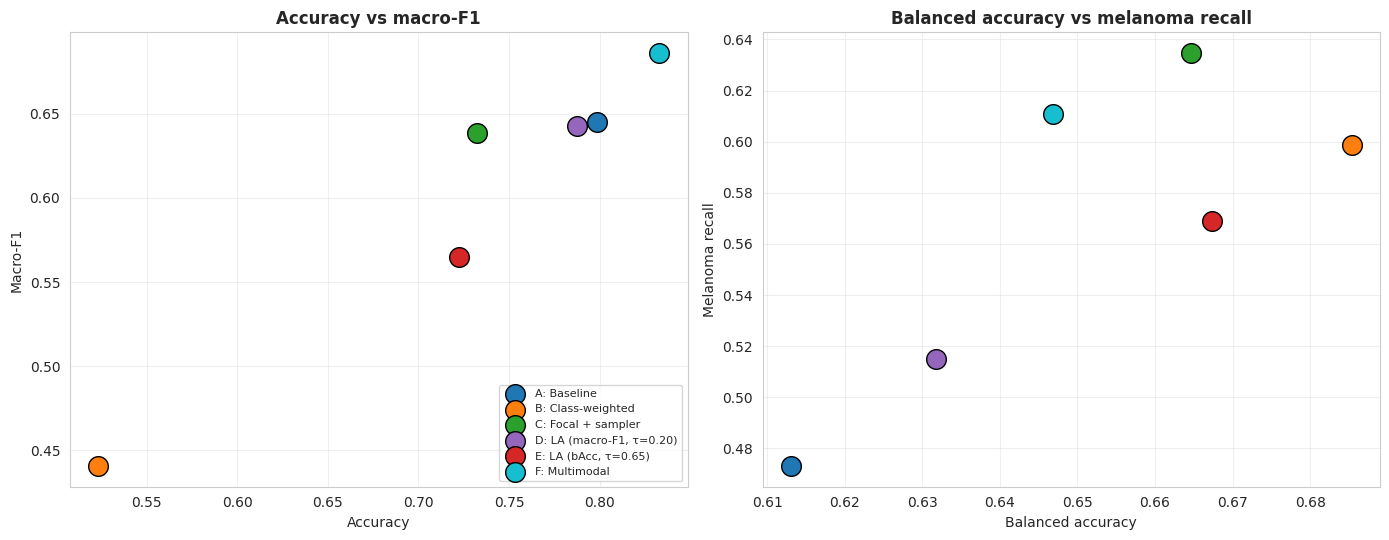

In [23]:
labels = ['A: Baseline', 'B: Class-weighted', 'C: Focal + sampler',
          f'D: LA (macro-F1, τ={tau_f1:.2f})', f'E: LA (bAcc, τ={tau_b:.2f})', 'F: Multimodal']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#9467bd', '#d62728', '#17becf']

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for n, (_, r) in enumerate(final_df.iterrows()):
    ax[0].scatter(r['Accuracy'], r['Macro-F1'], s=200, c=colors[n], label=labels[n], edgecolor='k', zorder=3)
    ax[1].scatter(r['Balanced-Acc'], r['Melanoma-Recall'], s=200, c=colors[n], edgecolor='k', zorder=3)
ax[0].set_xlabel('Accuracy')
ax[0].set_ylabel('Macro-F1')
ax[0].set_title('Accuracy vs macro-F1', fontweight='bold')
ax[0].legend(fontsize=8, loc='lower right')
ax[1].set_xlabel('Balanced accuracy')
ax[1].set_ylabel('Melanoma recall')
ax[1].set_title('Balanced accuracy vs melanoma recall', fontweight='bold')
for a in ax:
    a.grid(alpha=.3)
save_fig('tradeoff')
plt.show()

## 13. Clinical-style screening: malignant / pre-malignant vs benign
Group `mel + bcc + akiec` as the positive class and use the summed probability of those classes as a risk score.

**Protocol (no test-set leakage):** the decision threshold for a target sensitivity (90 % / 95 %) is chosen on the
**validation** set; sensitivity and specificity are then measured once on the **test** set.
ROC-AUC is threshold-free and computed on the test set.

This is a screening illustration on a small public dataset, not clinical validation.

In [24]:
def screening_eval(tag, targets=(0.90, 0.95)):
    d = PROBS[tag]
    yv = np.isin(d['Yv'], MAL_IDX).astype(int)
    yt = np.isin(d['Yt'], MAL_IDX).astype(int)
    sv, st = d['Pv'][:, MAL_IDX].sum(1), d['Pt'][:, MAL_IDX].sum(1)
    _, tpr_v, thr_v = roc_curve(yv, sv)
    out = dict(yt=yt, st=st, auc=roc_auc_score(yt, st), ops=[])
    for target in targets:
        t = thr_v[np.argmax(tpr_v >= target)]            # first threshold reaching the target sensitivity on val
        pred = (st >= t).astype(int)
        out['ops'].append(dict(target=target, thr=float(t),
                               sens=float((pred[yt == 1] == 1).mean()),
                               spec=float((pred[yt == 0] == 0).mean()),
                               missed=int(((pred == 0) & (yt == 1)).sum()), n_pos=int(yt.sum())))
    return out


SCREEN = {tag: screening_eval(tag) for tag in ['A_baseline', 'F_multimodal']}

rows = []
for tag, s in SCREEN.items():
    for op in s['ops']:
        rows.append(dict(Model=tag, ROC_AUC=round(s['auc'], 4), Target_sens=op['target'],
                         Val_threshold=round(op['thr'], 4), Test_sens=round(op['sens'], 4),
                         Test_spec=round(op['spec'], 4), Missed=f"{op['missed']}/{op['n_pos']}"))
screen_df = pd.DataFrame(rows)
screen_df.to_csv(f'{PROJ}/screening_results.csv', index=False)
print(screen_df.to_string(index=False))

       Model  ROC_AUC  Target_sens  Val_threshold  Test_sens  Test_spec Missed
  A_baseline   0.9072         0.90         0.1563     0.8793     0.7434 35/290
  A_baseline   0.9072         0.95         0.0762     0.9552     0.6147 13/290
F_multimodal   0.9324         0.90         0.1316     0.9138     0.7838 25/290
F_multimodal   0.9324         0.95         0.0647     0.9586     0.6840 12/290


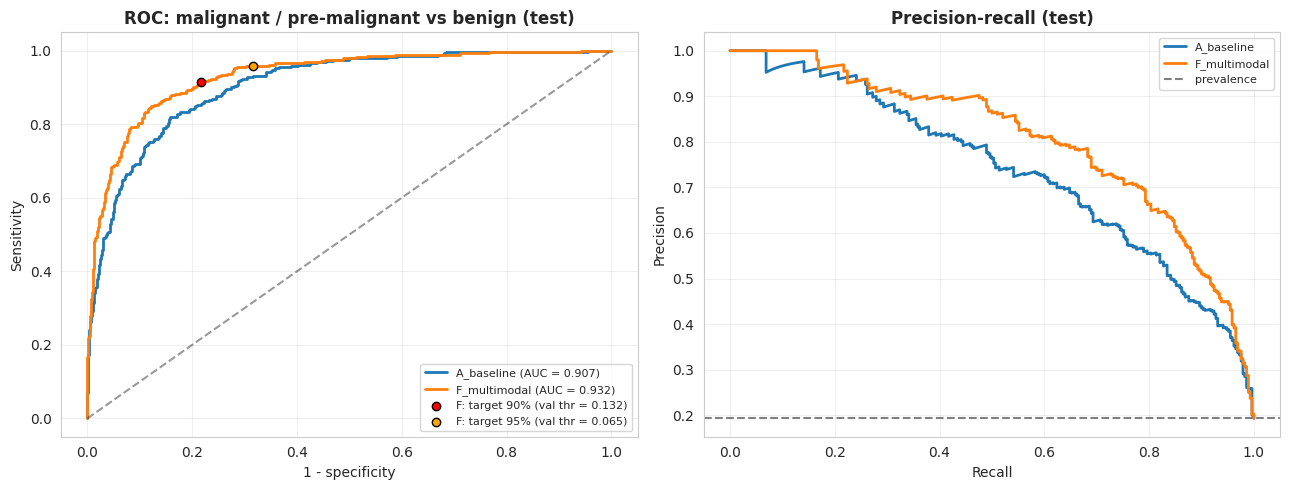

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for tag, s in SCREEN.items():
    fpr, tpr, _ = roc_curve(s['yt'], s['st'])
    ax[0].plot(fpr, tpr, lw=2, label=f"{tag} (AUC = {s['auc']:.3f})")
    pr, rc, _ = precision_recall_curve(s['yt'], s['st'])
    ax[1].plot(rc, pr, lw=2, label=tag)
for op, col in zip(SCREEN['F_multimodal']['ops'], ['red', 'orange']):
    ax[0].scatter(1 - op['spec'], op['sens'], c=col, edgecolor='k', zorder=5,
                  label=f"F: target {op['target']:.0%} (val thr = {op['thr']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', alpha=.4)
ax[0].set_xlabel('1 - specificity')
ax[0].set_ylabel('Sensitivity')
ax[0].set_title('ROC: malignant / pre-malignant vs benign (test)', fontweight='bold')
ax[0].legend(fontsize=8)
ax[1].axhline(SCREEN['F_multimodal']['yt'].mean(), ls='--', c='gray', label='prevalence')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[1].set_title('Precision-recall (test)', fontweight='bold')
ax[1].legend(fontsize=8)
for a in ax:
    a.grid(alpha=.3)
save_fig('roc_screening')
plt.show()

## 14. Explainability with Grad-CAM
Grad-CAM on the multimodal model (target layer: the last convolution of the EfficientNet backbone) shows which
image regions drive the predicted class. Top row: input; bottom row: heatmap.
Shown: one correctly classified test example per class and up to three missed melanomas.
Heatmaps are a plausibility check, not proof that the model reasons like a clinician.

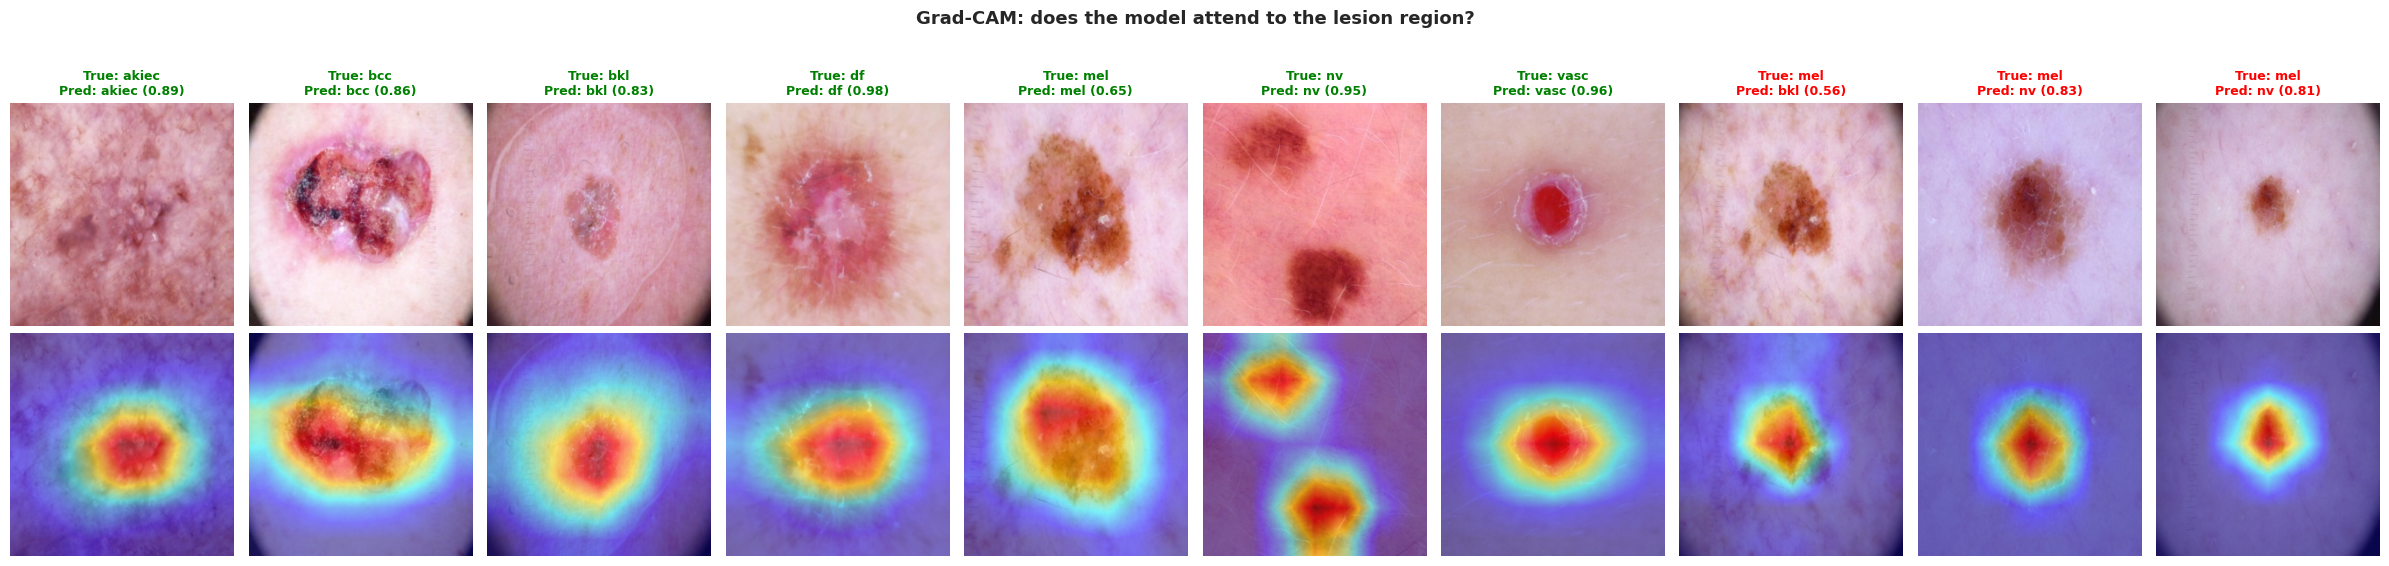

In [26]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


class FusionForCAM(nn.Module):
    # Grad-CAM calls model(image) only, so the metadata vector is attached to the wrapper beforehand
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.meta = None

    def forward(self, x):
        return self.net(x, self.meta.expand(x.shape[0], -1))


model_F.eval()
cam_model = FusionForCAM(model_F).eval()
cam = GradCAM(model=cam_model, target_layers=[model_F.cnn.conv_head])


def explain(x, meta):
    # x: normalized CHW tensor (cpu); meta: float32 numpy vector. Returns class probabilities and a heatmap overlay.
    cam_model.meta = torch.from_numpy(meta).unsqueeze(0).to(DEVICE)
    xb = x.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = cam_model(xb).softmax(1)[0].cpu().numpy()
    g = cam(input_tensor=xb, targets=[ClassifierOutputTarget(int(probs.argmax()))])[0]
    heat = show_cam_on_image(inv(x.cpu()).astype(np.float32), g, use_rgb=True)
    return probs, heat


Pt_F = PROBS['F_multimodal']['Pt']
pred_F = Pt_F.argmax(1)
picks = []
for c in range(NUM_CLASSES):
    idx = np.where((Yt == c) & (pred_F == c))[0]
    if len(idx):
        picks.append((int(idx[0]), 'CORRECT'))
picks += [(int(i), 'MISSED MEL') for i in np.where((Yt == MEL) & (pred_F != MEL))[0][:3]]

test_ds_mm = SkinDS(test_df, eval_tf, META['test'])
fig, axes = plt.subplots(2, len(picks), figsize=(2.4 * len(picks), 5.6))
for k, (i, tag) in enumerate(picks):
    x, m, y = test_ds_mm[i]
    probs, heat = explain(x, m.numpy())
    axes[0, k].imshow(inv(x))
    axes[0, k].axis('off')
    axes[0, k].set_title(f'True: {CLASSES[y]}\nPred: {CLASSES[int(probs.argmax())]} ({probs.max():.2f})',
                         fontsize=9, fontweight='bold', color='green' if tag == 'CORRECT' else 'red')
    axes[1, k].imshow(heat)
    axes[1, k].axis('off')
plt.suptitle('Grad-CAM: does the model attend to the lesion region?', fontweight='bold', fontsize=13, y=1.03)
save_fig('gradcam')
plt.show()

## 15. Gradio demo
The demo serves the **multimodal model (F)**: upload a dermoscopic image and enter age, sex and lesion site.
It shows class probabilities, a Grad-CAM overlay and a screening flag that uses the **validation-selected
95 %-sensitivity threshold** from section 13. Uploaded images are resized exactly like the training cache
(256x256) before the usual centre crop.

The public share link is temporary (about one week). Record a screen capture or screenshots for your portfolio
instead of linking it.

In [27]:
import gradio as gr

THR95 = SCREEN['F_multimodal']['ops'][1]['thr']          # threshold chosen on validation for 95 % sensitivity
SEX_CHOICES = [str(v) for v in ohe.categories_[0]]
LOC_CHOICES = [str(v) for v in ohe.categories_[1]]


def predict_demo(img, age, sex, loc):
    if img is None:
        return None, None, 'Please upload an image.'
    img = img.convert('RGB').resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR)    # same as the training cache
    x = eval_tf(img)
    meta = np.hstack([age_sc.transform(pd.DataFrame({'age': [float(age)]})),
                      ohe.transform(pd.DataFrame([[sex, loc]], columns=CAT))]).astype('float32')[0]
    probs, heat = explain(x, meta)
    mal = float(probs[MAL_IDX].sum())
    if mal >= THR95:
        flag = f'⚠️ REFER TO DERMATOLOGIST - malignancy score {mal:.3f} ≥ {THR95:.3f}'
    else:
        flag = f'✅ Low risk - malignancy score {mal:.3f} < {THR95:.3f}'
    return {LESION[c]: float(probs[i]) for i, c in enumerate(CLASSES)}, heat, flag


examples = [[test_df.iloc[i]['path'], float(test_df.iloc[i]['age']),
             str(test_df.iloc[i]['sex']), str(test_df.iloc[i]['localization'])] for i, _ in picks[:4]]

demo_kwargs = dict(
    fn=predict_demo,
    inputs=[gr.Image(type='pil', label='Dermoscopic image'),
            gr.Slider(0, 100, value=float(AGE_MED), step=1, label='Age'),
            gr.Dropdown(SEX_CHOICES, value='unknown' if 'unknown' in SEX_CHOICES else SEX_CHOICES[0], label='Sex'),
            gr.Dropdown(LOC_CHOICES, value='unknown' if 'unknown' in LOC_CHOICES else LOC_CHOICES[0],
                        label='Lesion localization')],
    outputs=[gr.Label(num_top_classes=7, label='Prediction'),
             gr.Image(label='Grad-CAM'),
             gr.Textbox(label='Screening flag (95% sensitivity threshold from validation)')],
    title='Skin Lesion Classifier - HAM10000 | EfficientNet-B0 + metadata',
    description='Educational demo only. Not for clinical use.',
    examples=examples,
)
try:
    demo = gr.Interface(flagging_mode='never', **demo_kwargs)        # gradio >= 5
except TypeError:
    demo = gr.Interface(allow_flagging='never', **demo_kwargs)       # older gradio

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ab651853871f724d28.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 16. Summary and limitations
**Where to find the numbers:** `results_final.csv` (model comparison), `screening_results.csv` (screening),
`classification_report.csv` (per-class report), figures in `figs/`.

**Take-aways to verify against your own run**
- Class re-weighting / balanced sampling (B, C) improve balanced accuracy and melanoma recall but can cost a lot of
  overall accuracy and macro-F1.
- Post-hoc logit adjustment (D, E) is a cheap, retraining-free way to move along the same trade-off; the validation
  gain for D is small and may not carry over to test.
- Adding patient metadata (F) is the comparison that isolates the effect of a new information source.

**Limitations**
- Single run per model and a single split; the test set has very few examples of rare classes
  (about 20 for `df` and `vasc`), so small metric differences are within noise. Repeating with several seeds or
  bootstrapping the test set would quantify this.
- HAM10000 has no patient ID: the split is at lesion level, so one patient could appear in several splits.
- Images come from a limited set of clinics and devices; generalization to other populations is untested.
- Screening thresholds are selected on validation data, but the validation set is also small.
- Educational project, not validated for clinical use.